In [7]:
import numpy as np
import pandas as pd
states = ["New","Active","Churned"]
matrix_1=np.array([[0.50,0.40,0.10],[0.10,0.70,0.20],[0.00,0.00,1.00]]) # it always goes from row to column
transition_matrix=pd.DataFrame(matrix_1,columns=states,index=states)
print(transition_matrix)

print("\n Row Sum:- ")
print(matrix_1.sum(axis=1))


         New  Active  Churned
New      0.5     0.4      0.1
Active   0.1     0.7      0.2
Churned  0.0     0.0      1.0

 Row Sum:- 
[1. 1. 1.]


In [8]:
initial_distribution = np.array([1,0,0])
distribution_1 = initial_distribution @ matrix_1
print("Distribution after 1 period:- ")
for state, probability in zip(states, distribution_1):
    print(f"{state}: {probability:.2f}")


Distribution after 1 period:- 
New: 0.50
Active: 0.40
Churned: 0.10


Q3) Prdict the customer-state distribution after 5 period

In [9]:
distribution = initial_distribution.copy()
for _ in range(5):
    distribution = distribution @ matrix_1
print("Distribution after 5 periods:- ")
for state, probability in zip(states, distribution):
    print(f"{state}: {probability:.2f}")

Distribution after 5 periods:- 
New: 0.11
Active: 0.33
Churned: 0.56


In [15]:
np.random.seed(42)
current_state = 0
customer_history = [states[current_state]]
for _ in range(10):
  current_state = np.random.choice(len(states),p=matrix_1[current_state])
  customer_history.append(states[current_state])
print("Customer State History:- ")
print(customer_history)


Customer State History:- 
['New', 'New', 'Churned', 'Churned', 'Churned', 'Churned', 'Churned', 'Churned', 'Churned', 'Churned', 'Churned']


In [18]:
np.random.seed(42)
n_customer =1000
n_period = 10

customers= np.zeros(n_customer, dtype=int)
results=[]
for _ in range(n_period+1):
  counts = np.bincount(customers,minlength=3)
  proportions = counts / n_customer

  results.append([_,proportions[0],proportions[1],proportions[2]])
  new_customers = np.array([np.random.choice(3,p=matrix_1[state]) for state in customers])
  customers = new_customers
  results_df=pd.DataFrame(results,columns=["Period","New","Active","Churned"])
print(results_df)

    Period    New  Active  Churned
0        0  1.000   0.000    0.000
1        1  0.503   0.397    0.100
2        2  0.284   0.491    0.225
3        3  0.193   0.456    0.351
4        4  0.145   0.389    0.466
5        5  0.113   0.338    0.549
6        6  0.084   0.275    0.641
7        7  0.068   0.230    0.702
8        8  0.069   0.191    0.740
9        9  0.058   0.164    0.778
10      10  0.046   0.136    0.818


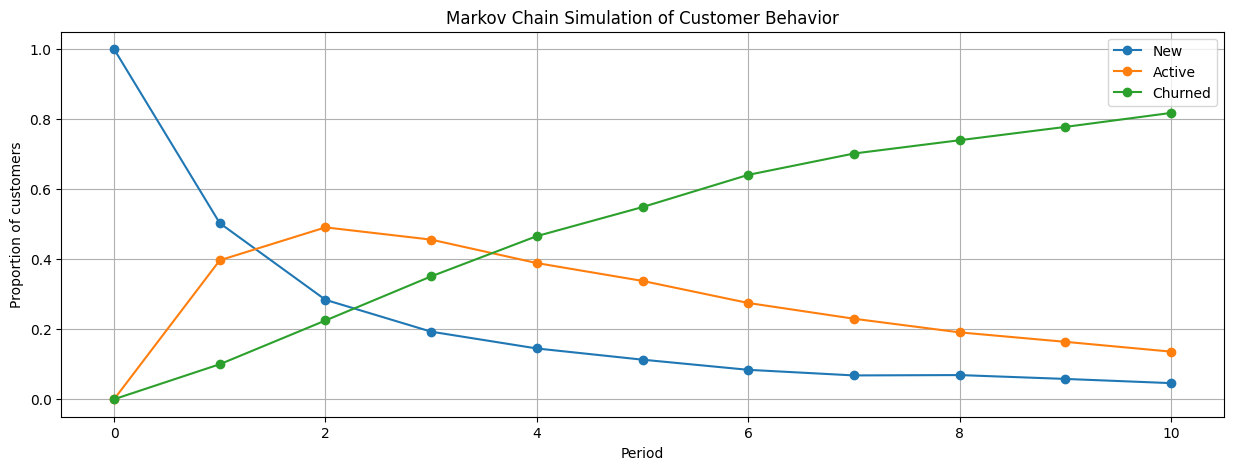

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.plot(results_df["Period"],results_df["New"],marker='o',label="New")
plt.plot(results_df["Period"],results_df["Active"],marker='o',label="Active")
plt.plot(results_df["Period"],results_df["Churned"],marker='o',label="Churned")
plt.xlabel("Period")
plt.ylabel("Proportion of customers")
plt.title("Markov Chain Simulation of Customer Behavior")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
max_chrun_period= results_df.loc[results_df['Churned'].idxmax()]
print("Maximum Churn Period:- ")
print(max_chrun_period)

Maximum Churn Period:- 
Period     10.000
New         0.046
Active      0.136
Churned     0.818
Name: 10, dtype: float64
